# Figure 5: Long-Term Trends and Firm Concentration in Privacy Patenting (1999–2021)

| Item | Description |
|---|---|
| Goal | Construct and export Figure 5 of the proposal (Panels A and B): Long-Term Trends and Firm Concentration in Privacy Patenting. |
| Input | `sample_firm_privacy_patents.csv` from `X1.1 - Data for Matching and Patent Analysis`. |
| Output | Figure 5 Panels A and B saved to `R - Results/R1.1 - Figures/R1.1.3 - X1 - Example of Research Enabled by LLM Pipeline/R1.1.3.2 - Figure 5 - Long-Term Trends and Firm Concentration in Privacy Patenting`. Summary tables saved to `R - Results/R1.2 - Tables/R1.2.2 - X1 - Example of Research Enabled by LLM Pipeline/R1.2.2.2 - X1.3 - Notebooks for Analysis/Figure 5`. |
| Panels | **Panel A**: Aggregate Filing Trends across Privacy CPC Codes, 1999–2021.<br>**Panel B**: Top 20 Patent Assignees by Privacy Technology Group. |


## Step 1. Import packages


In [1]:
from pathlib import Path
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import numpy as np
import pandas as pd
from IPython.display import Image, Markdown, display


## Step 2. Define file locations, period, style settings, and topic groups


In [2]:
PROJECT_FOLDER = Path.cwd().resolve().parents[1]  # <section>/<subfolder>/ sits two levels below the clone
SCRATCH_FOLDER = Path("/scratch1/acroh/projects/LLM-Text-Analysis-and-Synthesis")  # the one line to change on another machine
NOTEBOOK_SUBFOLDER = Path("X1 - Example of Research Enabled by LLM Pipeline/X1.2 - Privacy Patents and Topic Relevance - 5 Codes by MM")
NOTEBOOK_NAME = "X1.2.2 - Figure - Privacy Patents by Topic Group"  # the notebook filename without .ipynb
DATA_FOLDER = PROJECT_FOLDER / "X1 - Example of Research Enabled by LLM Pipeline/X1.1 - Data for Matching and Patent Analysis"
PATENTS_CSV = DATA_FOLDER / "sample_firm_privacy_patents.csv"  # X1.1.2
FIGURE_FOLDER = PROJECT_FOLDER / "R - Results/R1.1 - Figures/R1.1.3 - X1 - Example of Research Enabled by LLM Pipeline/R1.1.3.2 - Figure 5 - Long-Term Trends and Firm Concentration in Privacy Patenting"
TABLE_FOLDER = PROJECT_FOLDER / "R - Results/R1.2 - Tables/R1.2.2 - X1 - Example of Research Enabled by LLM Pipeline/R1.2.2.2 - X1.3 - Notebooks for Analysis/Figure 5"
for folder in (FIGURE_FOLDER, TABLE_FOLDER):
    folder.mkdir(parents=True, exist_ok=True)

PERIOD_START, PERIOD_END = 1999, 2021
PERIOD_WORDS = "1999 to 2021"
SAMPLE_WORDS = "the 1,058 firms of the all-years T3 sample (every firm with a 10-K in the sample, fiscal 1999 to 2025), linked to their KPSS patents in X1.1.1"
SOURCE = ("KPSS extended patent data (Kogan, Papanikolaou, Seru, and Stoffman, 2017, updated to 2025) with the authors' CPC match file; the focal privacy CPC codes "
          "(Data/privacy_cpc_codes_MM_102926.xlsx); sample firms from the 10-K sample of T3 (SEC EDGAR); authors' calculations")  # the two names the figure notes use
FIGURE_WIDTH, FIGURE_HEIGHT = 9, 6
MARGIN_INCHES = 0.5 / 2.54
EXPORT_DPI = 300
TOP_N_FIRMS = 20

BLACK = "#000000"
ZERO_LINE_WIDTH = 0.8
THOUSANDS = ticker.StrMethodFormatter("{x:,.0f}")
by_year = pd.DataFrame({"filing_year": range(PERIOD_START, PERIOD_END + 1)})

# S3 styling
plt.rcParams["font.family"] = "serif"
plt.rcParams["font.serif"] = ["Times New Roman", "DejaVu Serif", "serif"]
plt.rcParams["axes.edgecolor"] = "#333333"
plt.rcParams["axes.linewidth"] = 0.8

# Topic Groups Definition
GROUP_MAPPING_4 = {
    "G06Q30/0269": "Tracking User Profiles and Data",
    "G06Q30/0255": "Tracking User Profiles and Data",
    "G06Q30/0261": "Tracking User Profiles and Data",
    "H04W12/02": "Protecting Privacy and Anonymity (PII)",
    "G06F21/6254": "Anonymizing or Decorrelating Data",
    "H04W12/033": "Anonymizing or Decorrelating Data",
    "H04W12/03": "Protecting Confidentiality (Encryption)",
}

ORDER_4 = [
    "Tracking User Profiles and Data",
    "Protecting Privacy and Anonymity (PII)",
    "Anonymizing or Decorrelating Data",
    "Protecting Confidentiality (Encryption)",
]

LABELS_4 = [
    "Tracking User Profiles and Data (G06Q 30/0269, 30/0255, 30/0261)",
    "Protecting Privacy and Anonymity (PII) (H04W 12/02)",
    "Anonymizing or Decorrelating Data (G06F 21/6254, H04W 12/033)",
    "Protecting Confidentiality by Encryption (H04W 12/03)",
]

COLORS_4 = ["black", "dodgerblue", "slategrey", "#00ACC1"]
MARKERS_4 = ["o", "s", "^", "D"]
STYLES_4 = ["-", "--", "-.", ":"]

GROUP_STYLES_DICT = {
    lbl: (col, mkr, stl) for lbl, col, mkr, stl in zip(LABELS_4, COLORS_4, MARKERS_4, STYLES_4)
}

GROUP_MAPPING_FULL = {
    "G06Q30/0269": LABELS_4[0],
    "G06Q30/0255": LABELS_4[0],
    "G06Q30/0261": LABELS_4[0],
    "H04W12/02": LABELS_4[1],
    "G06F21/6254": LABELS_4[2],
    "H04W12/033": LABELS_4[2],
    "H04W12/03": LABELS_4[3],
}

def title_case_name(name):
    return " ".join(word[0].upper() + word[1:].lower() if word.isalpha() or "." in word else word for word in name.split())

print("Setup complete.")


Setup complete.


## Step 3. Load privacy patents dataset


In [3]:
df_patents = pd.read_csv(PATENTS_CSV)
df_patents["filing_date"] = pd.to_datetime(df_patents["filing_date"])
df_patents["filing_year"] = df_patents["filing_date"].dt.year

patents_in_period = df_patents.loc[df_patents["filing_year"].between(PERIOD_START, PERIOD_END)].copy()
focal_matches = patents_in_period.loc[patents_in_period["privacy_cpc"].isin(GROUP_MAPPING_4.keys())].copy()
focal_matches["group"] = focal_matches["privacy_cpc"].map(GROUP_MAPPING_4)

print(f"Total patent-code rows in focal groups: {len(focal_matches):,}")
print(f"Distinct patents across all 4 groups: {focal_matches['patent_num'].nunique():,}")
for grp in ORDER_4:
    print(f"  {grp}: {focal_matches[focal_matches['group'] == grp]['patent_num'].nunique():,} unique patents")


Total patent-code rows in focal groups: 6,015
Distinct patents across all 4 groups: 5,244
  Tracking User Profiles and Data: 2,764 unique patents
  Protecting Privacy and Anonymity (PII): 1,519 unique patents
  Anonymizing or Decorrelating Data: 954 unique patents
  Protecting Confidentiality (Encryption): 142 unique patents


## Step 4. Figure 1: Privacy Patents by Filing Year and Topic Group (Normalized to Share of Topic Group Total)

Filing trends from 1999 to 2021 for the four focal privacy topic groups, normalized as the share of all sample-firm patents within each topic group across the sample period (the denominator is the total number of patents in each group). The legend below the X-title reports each group's total distinct patent count N.

**Privacy Patents Filed by Sample Firms by Filing Year and Topic Group (Share of Group Total), 1999 to 2021**

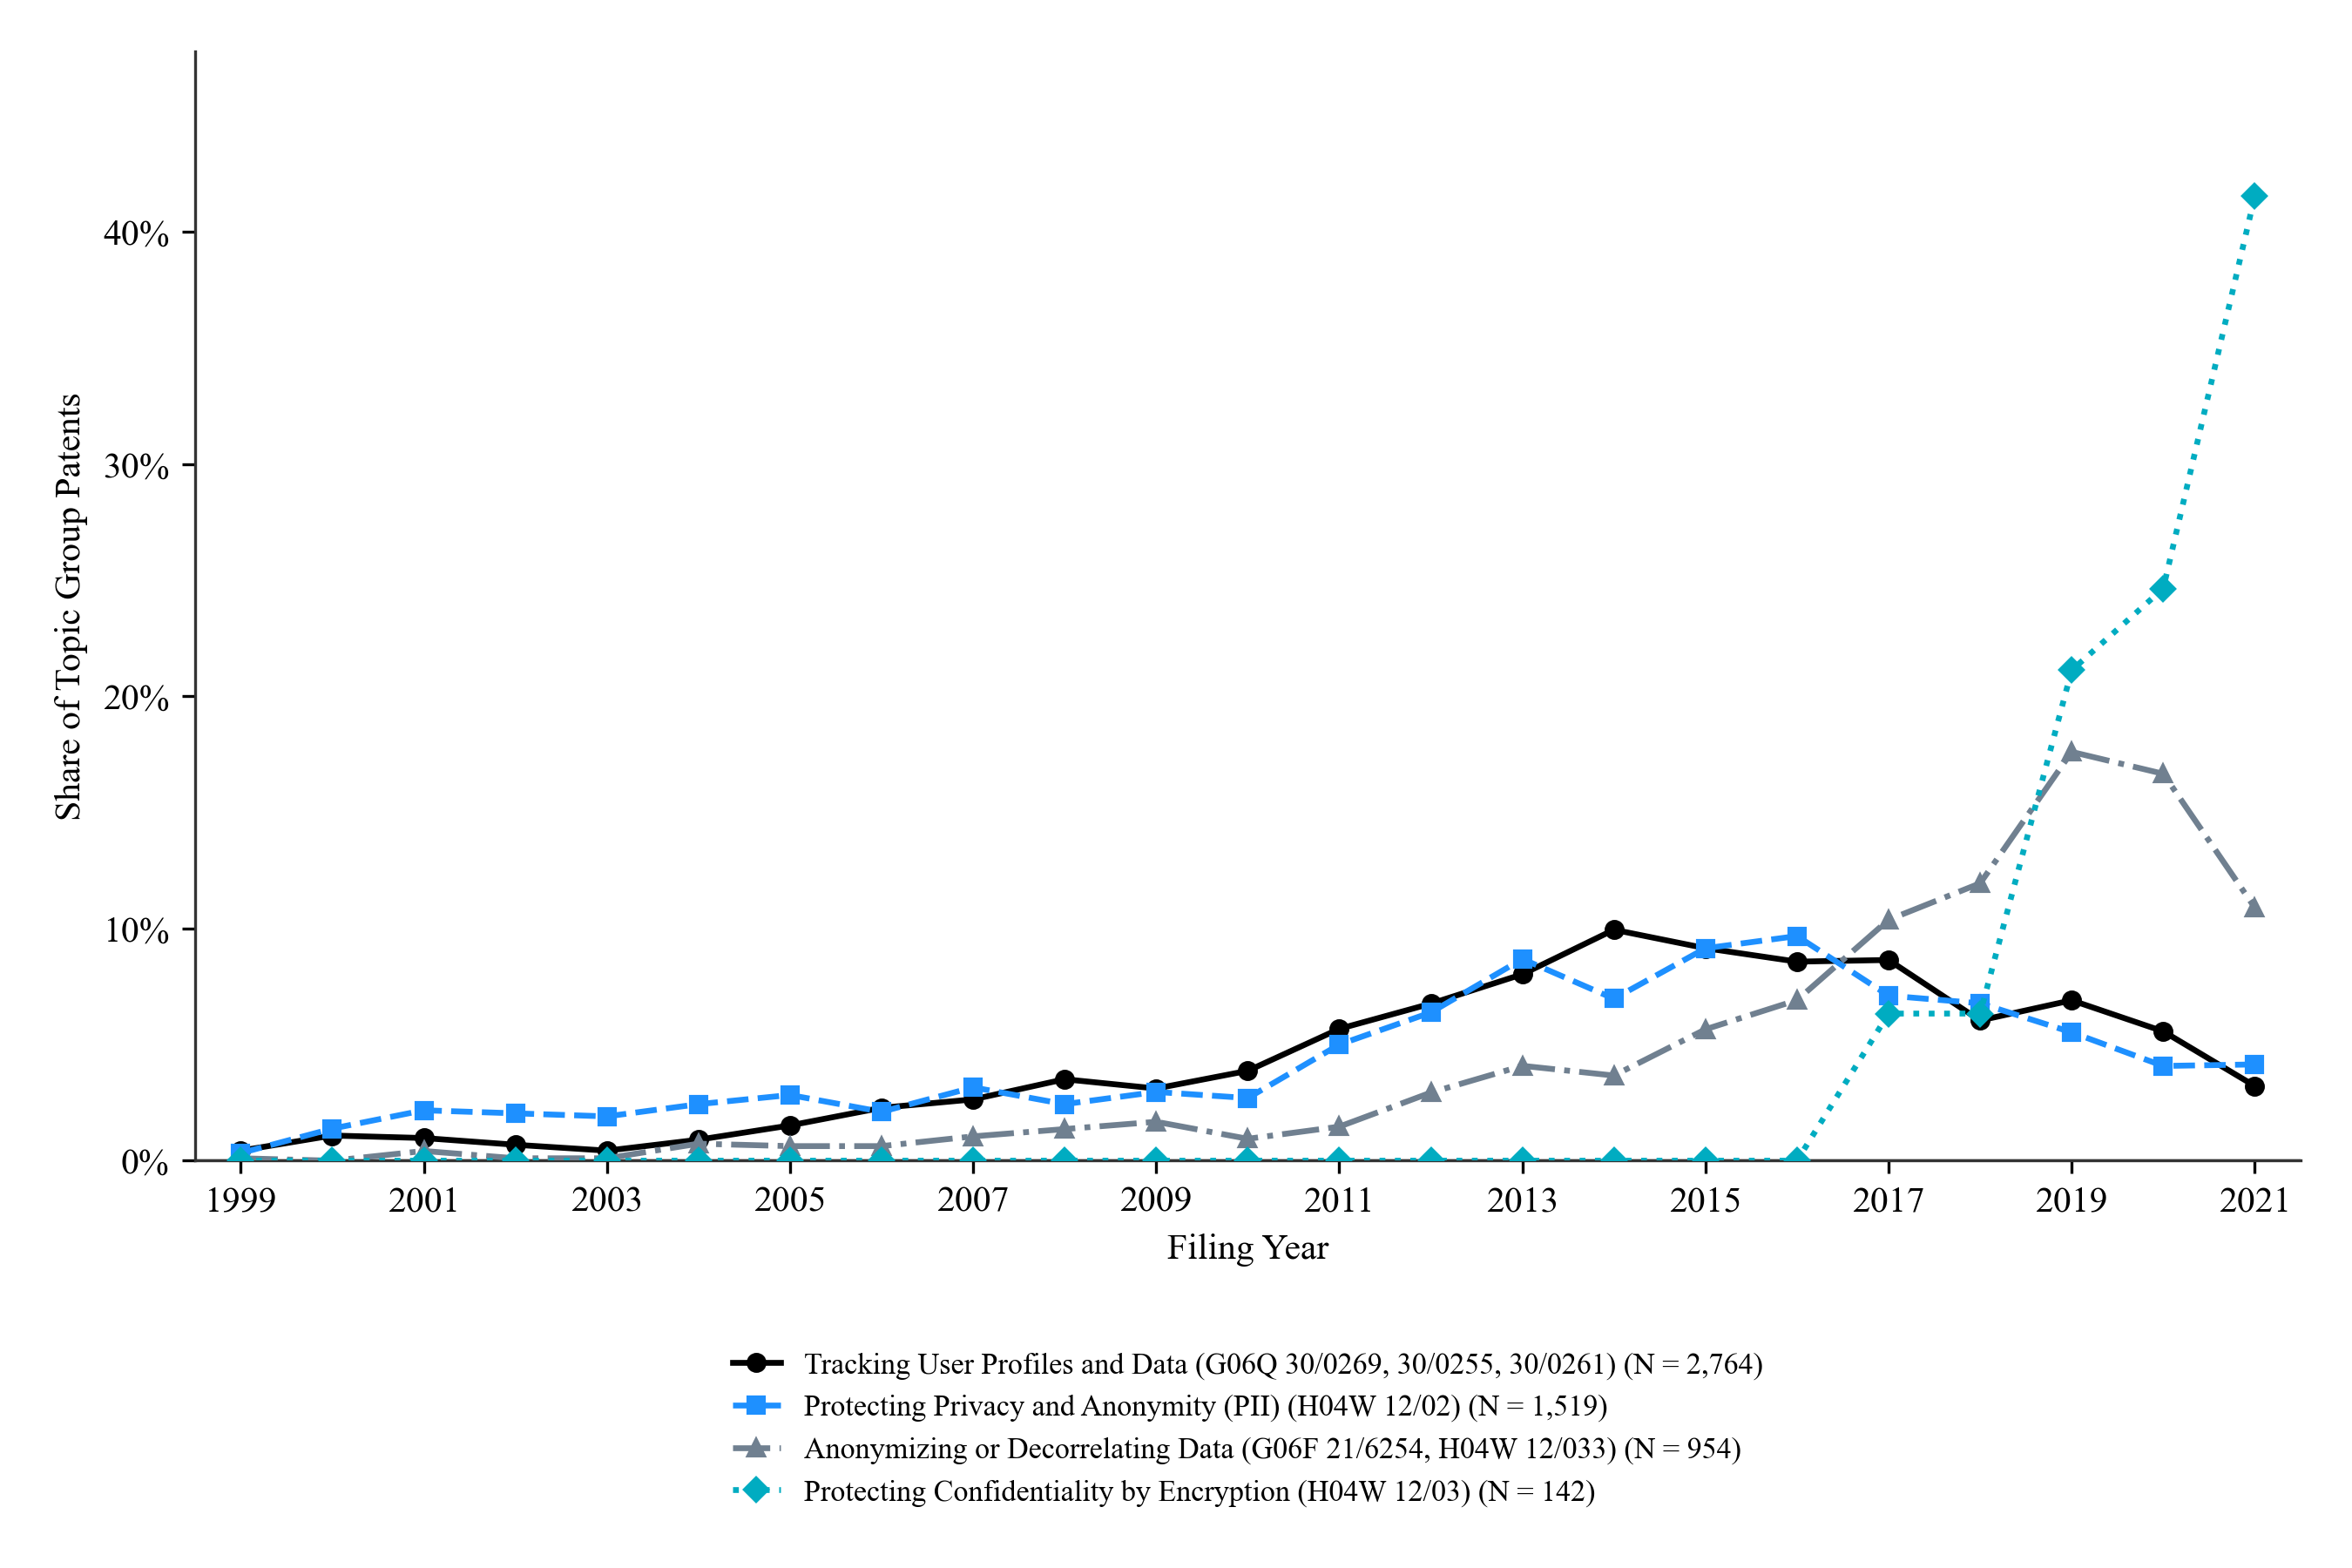

*Notes*: Filing trends from 1999 to 2021 for the four focal privacy topic groups, normalized as the share of all sample-firm patents within each topic group (denominator is each group's total distinct patents). Topic groups: (1) Tracking User Profiles and Data (G06Q 30/0269, 30/0255, 30/0261; N = 2,764), (2) Protecting Privacy and Anonymity [PII] (H04W 12/02; N = 1,519), (3) Anonymizing or Decorrelating Data (G06F 21/6254, H04W 12/033; N = 954), and (4) Protecting Confidentiality by Encryption (H04W 12/03; N = 142). Total distinct privacy patents across groups: N = 5,244. The sample firms are the 1,058 firms of the all-years T3 sample (every firm with a 10-K in the sample, fiscal 1999 to 2025), linked to their KPSS patents in X1.1.1.

*Source*: KPSS extended patent data (Kogan, Papanikolaou, Seru, and Stoffman, 2017, updated to 2025) with the authors' CPC match file; the focal privacy CPC codes (Data/privacy_cpc_codes_MM_102926.xlsx); sample firms from the 10-K sample of T3 (SEC EDGAR); authors' calculations.

Saved PNG, SVG, and PDF: /Users/milanmiric/Documents/Research/Active Papers/LLM Text Sumarization and Data Extraction/R - Results/R1.1 - Figures/R1.1.3 - X1 - Example of Research Enabled by LLM Pipeline/R1.1.3.2 - Figure 5 - Long-Term Trends and Firm Concentration in Privacy Patenting/fig_8_privacy_patent_count_by_filing_year_and_cpc_code; data in privacy_patents_by_year_and_code.csv


In [4]:
figure_number = 8
figure_name = "fig_8_privacy_patent_count_by_filing_year_and_cpc_code"
title = f"Privacy Patents Filed by Sample Firms by Filing Year and Topic Group (Share of Group Total), {PERIOD_WORDS}"
x_title = "Filing Year"
y_title = "Share of Topic Group Patents"
LEGEND_COLUMNS = 1

# Topic groups
g1_pats = patents_in_period[patents_in_period["privacy_cpc"].isin(["G06Q30/0269", "G06Q30/0255", "G06Q30/0261"])]
g2_pats = patents_in_period[patents_in_period["privacy_cpc"] == "H04W12/02"]
g3_pats = patents_in_period[patents_in_period["privacy_cpc"].isin(["G06F21/6254", "H04W12/033"])]
g4_pats = patents_in_period[patents_in_period["privacy_cpc"] == "H04W12/03"]

n1 = g1_pats["patent_num"].nunique()
n2 = g2_pats["patent_num"].nunique()
n3 = g3_pats["patent_num"].nunique()
n4 = g4_pats["patent_num"].nunique()

cnt1 = g1_pats.groupby("filing_year")["patent_num"].nunique().reindex(by_year["filing_year"], fill_value=0)
cnt2 = g2_pats.groupby("filing_year")["patent_num"].nunique().reindex(by_year["filing_year"], fill_value=0)
cnt3 = g3_pats.groupby("filing_year")["patent_num"].nunique().reindex(by_year["filing_year"], fill_value=0)
cnt4 = g4_pats.groupby("filing_year")["patent_num"].nunique().reindex(by_year["filing_year"], fill_value=0)

# Normalize to share of all patents within each topic group
share1 = (cnt1 / n1).fillna(0)
share2 = (cnt2 / n2).fillna(0)
share3 = (cnt3 / n3).fillna(0)
share4 = (cnt4 / n4).fillna(0)

LABELS_WITH_N = [
    f"Tracking User Profiles and Data (G06Q 30/0269, 30/0255, 30/0261) (N = {n1:,})",
    f"Protecting Privacy and Anonymity (PII) (H04W 12/02) (N = {n2:,})",
    f"Anonymizing or Decorrelating Data (G06F 21/6254, H04W 12/033) (N = {n3:,})",
    f"Protecting Confidentiality by Encryption (H04W 12/03) (N = {n4:,})",
]

df_plot = pd.DataFrame({
    LABELS_WITH_N[0]: share1,
    LABELS_WITH_N[1]: share2,
    LABELS_WITH_N[2]: share3,
    LABELS_WITH_N[3]: share4,
}, index=by_year["filing_year"])

# Export CSV with raw counts and normalized shares
csv_out = pd.DataFrame({
    "filing_year": by_year["filing_year"],
    "count_tracking_user_profiles_G06Q": cnt1.values,
    "share_tracking_user_profiles": share1.values,
    "count_protecting_privacy_PII_H04W12_02": cnt2.values,
    "share_protecting_privacy_PII": share2.values,
    "count_anonymizing_data_G06F_H04W": cnt3.values,
    "share_anonymizing_data": share3.values,
    "count_confidentiality_encryption_H04W12_03": cnt4.values,
    "share_confidentiality_encryption": share4.values,
})
csv_out.to_csv(TABLE_FOLDER / "privacy_patents_by_year_and_code.csv", index=False)

fig, axis = plt.subplots(figsize=(FIGURE_WIDTH, FIGURE_HEIGHT))
fig.subplots_adjust(left=0.1, right=1 - MARGIN_INCHES / FIGURE_WIDTH, top=1 - MARGIN_INCHES / FIGURE_HEIGHT, bottom=0.25)

series_config = [
    (LABELS_WITH_N[0], "black", "o", "-"),
    (LABELS_WITH_N[1], "dodgerblue", "s", "--"),
    (LABELS_WITH_N[2], "slategrey", "^", "-."),
    (LABELS_WITH_N[3], "#00ACC1", "D", ":"),
]

legend_handles = []
for col, color, marker, pattern in series_config:
    line, = axis.plot(df_plot.index, df_plot[col], color=color, linestyle=pattern, linewidth=1.6, marker=marker, markersize=4.5,
                      label=col, zorder=3)
    legend_handles.append(line)

axis.axhline(0, color=BLACK, linewidth=ZERO_LINE_WIDTH, zorder=2)
axis.set_xticks(range(PERIOD_START, PERIOD_END + 1, 2))
axis.set_xlim(PERIOD_START - 0.5, PERIOD_END + 0.5)
axis.set_ylim(0, df_plot.max().max() * 1.15)
axis.yaxis.set_major_formatter(ticker.PercentFormatter(1.0, decimals=0))
axis.set_xlabel(x_title)
axis.set_ylabel(y_title)
axis.spines[["top", "right"]].set_visible(False)

fig.canvas.draw()
renderer = fig.canvas.get_renderer()
margin_pixels = MARGIN_INCHES * fig.dpi
left_shift = (margin_pixels - axis.yaxis.label.get_window_extent(renderer).x0) / fig.bbox.width
fig.subplots_adjust(left=fig.subplotpars.left + left_shift)
fig.canvas.draw()
x_title_box = axis.xaxis.label.get_window_extent(renderer)
bottom_shift = (margin_pixels - x_title_box.y0) / fig.bbox.height
fig.subplots_adjust(bottom=fig.subplotpars.bottom + bottom_shift)
fig.canvas.draw()

axis_center = (axis.get_window_extent(renderer).x0 + axis.get_window_extent(renderer).x1) / 2 / fig.bbox.width
x_title_box = axis.xaxis.label.get_window_extent(renderer)
legend = fig.legend(handles=legend_handles, loc="upper center", bbox_to_anchor=(axis_center, (x_title_box.y0 - margin_pixels) / fig.bbox.height),
                    bbox_transform=fig.transFigure, ncol=1, frameon=False, handlelength=1.6, columnspacing=2.0, fontsize=8.2)
fig.canvas.draw()
legend_box = legend.get_window_extent(renderer)
bottom_shift = (margin_pixels - legend_box.y0) / fig.bbox.height
fig.subplots_adjust(bottom=fig.subplotpars.bottom + bottom_shift)
fig.canvas.draw()
x_title_box = axis.xaxis.label.get_window_extent(renderer)
legend.set_bbox_to_anchor((axis_center, (x_title_box.y0 - margin_pixels) / fig.bbox.height))

for extension in ["png", "svg", "pdf"]:
    fig.savefig(FIGURE_FOLDER / f"{figure_name}.{extension}", dpi=EXPORT_DPI)
    fig.savefig(FIGURE_FOLDER / f"1 - Figure 5 Panel A - Aggregate Filing Trends across Privacy CPC Codes.{extension}", dpi=EXPORT_DPI)
plt.close(fig)

figure_notes = (f"Filing trends from {PERIOD_WORDS} for the four focal privacy topic groups, normalized as the share of all sample-firm patents within each topic group (denominator is each group's total distinct patents). "
                f"Topic groups: (1) Tracking User Profiles and Data (G06Q 30/0269, 30/0255, 30/0261; N = {n1:,}), "
                f"(2) Protecting Privacy and Anonymity [PII] (H04W 12/02; N = {n2:,}), "
                f"(3) Anonymizing or Decorrelating Data (G06F 21/6254, H04W 12/033; N = {n3:,}), and "
                f"(4) Protecting Confidentiality by Encryption (H04W 12/03; N = {n4:,}). "
                f"Total distinct privacy patents across groups: N = 5,244. The sample firms are {SAMPLE_WORDS}.")
display(Markdown(f"**{title}**"))
display(Image(filename=str(FIGURE_FOLDER / f"{figure_name}.png"), width=900))
display(Markdown(f"*Notes*: {figure_notes}\n\n*Source*: {SOURCE}."))
print(f"Saved PNG, SVG, and PDF: {FIGURE_FOLDER / figure_name}; data in privacy_patents_by_year_and_code.csv")


## Step 5. Figure 2: Top 20 Patenting Firms Split by Topic Group (Weighted)

The 20 firms with the most privacy patents across the four topic groups, the largest at the top, one stacked bar per firm. A bar's length is the firm's number of distinct privacy patents. Patents that span multiple topic groups are weighted equally across their groups (1/K) so that segments add up exactly to the firm's total distinct privacy patents without double-counting.


**Figure 2. Privacy Patents of the 20 Sample Firms With the Most, Split by Topic Group, 1999 to 2021**

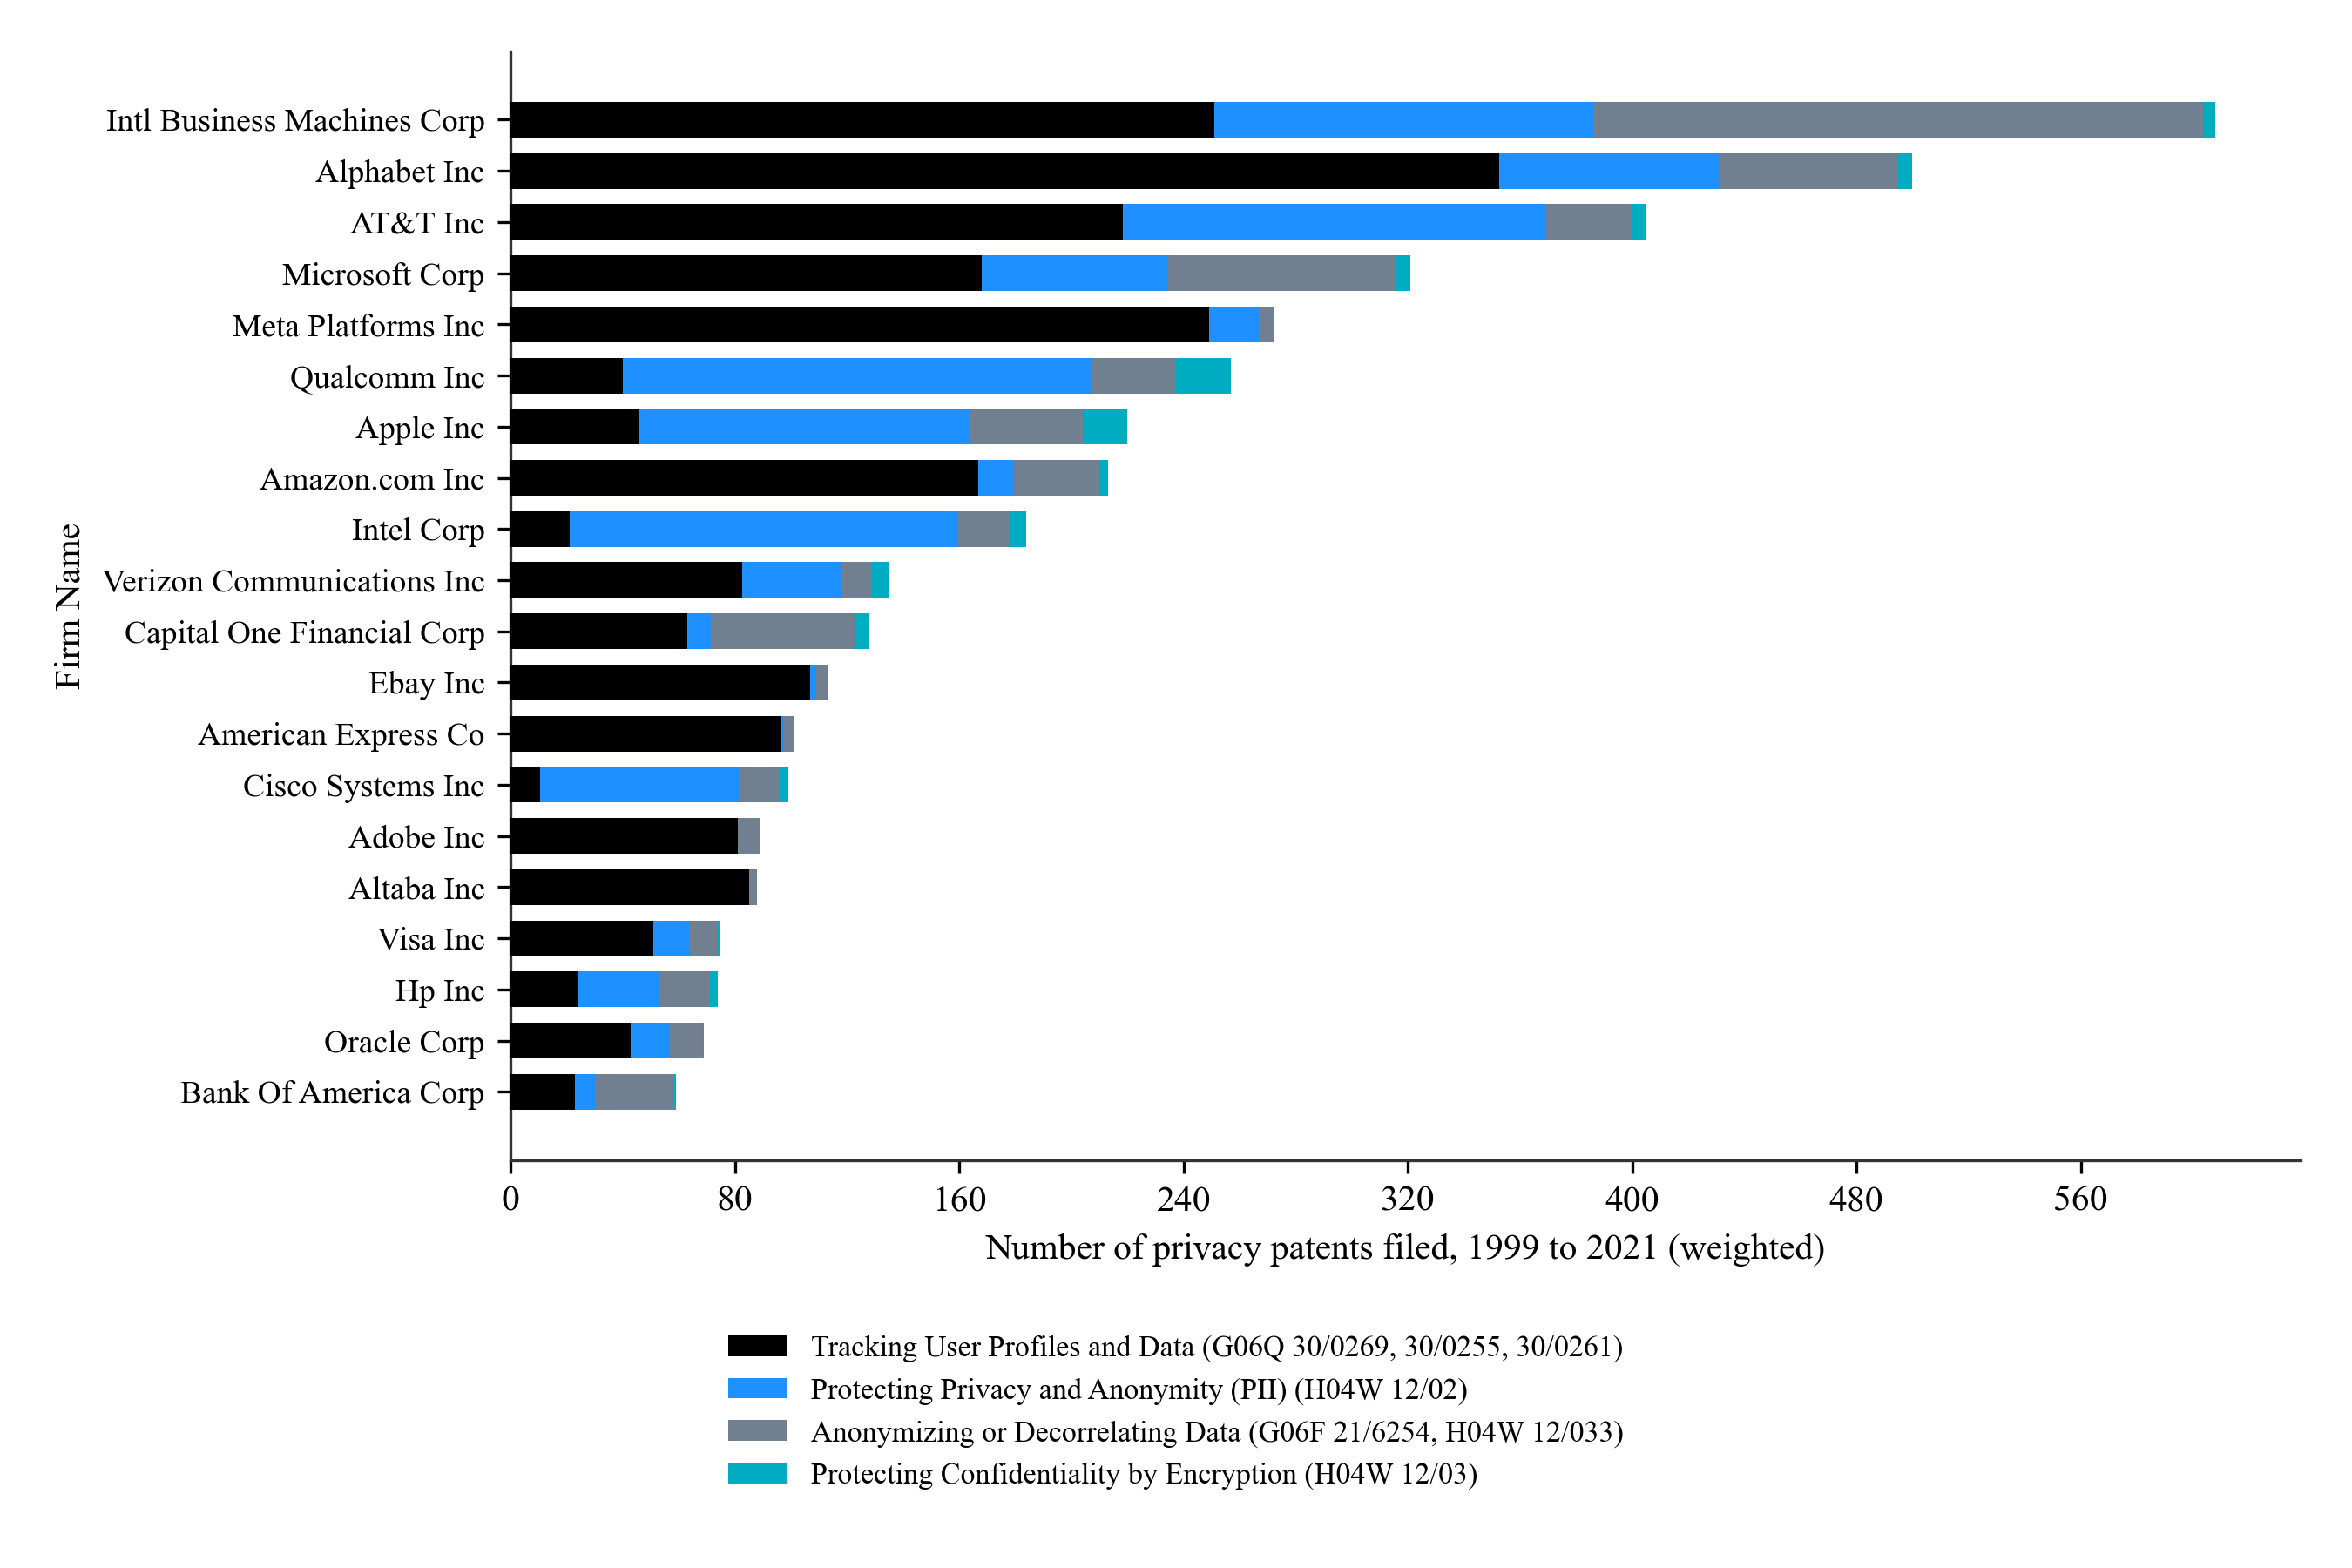

*Notes*: Each bar is one of the 20 sample firms with the most privacy patents across the four topic groups, the largest at the top; its length is the firm's number of distinct KPSS patents filed in 1999 to 2021. The four topic categories are: Tracking User Profiles and Data (G06Q 30/0269, 30/0255, 30/0261), Protecting Privacy and Anonymity [PII] (H04W 12/02), Anonymizing or Decorrelating Data (G06F 21/6254, H04W 12/033), and Protecting Confidentiality by Encryption (H04W 12/03), colored as shown in the legend. For patents carrying codes in multiple categories, each patent is weighted equally across its categories (weight 1/K) so that segments sum exactly to the firm's total distinct privacy patents without double-counting. Firm names are Compustat names in title case.

Saved PNG, SVG, and PDF: /Users/milanmiric/Documents/Research/Active Papers/LLM Text Sumarization and Data Extraction/R - Results/R1.1 - Figures/R1.1.3 - X1 - Example of Research Enabled by LLM Pipeline/R1.1.3.2 - Figure 5 - Long-Term Trends and Firm Concentration in Privacy Patenting/fig_9_top_firms_stacked_by_code; data in fig_9_stacked_counts.csv


In [5]:
figure_number = 2
figure_name = "fig_9_top_firms_stacked_by_code"
TOP_N_FIRMS = 20
figure_title = f"Figure {figure_number}. Privacy Patents of the {TOP_N_FIRMS} Sample Firms With the Most, Split by Topic Group, {PERIOD_WORDS}"

by_firm_focal = focal_matches.groupby(["gvkey", "conm"])["patent_num"].nunique().sort_values(ascending=False).reset_index()
by_firm_focal.rename(columns={"patent_num": "n_privacy_patents"}, inplace=True)
top_firms = by_firm_focal.head(TOP_N_FIRMS)

# Distinct topic groups per patent for weighting
groups_per_patent = focal_matches.groupby("patent_num")["group"].transform("nunique")
focal_matches["weight"] = 1.0 / groups_per_patent
patent_group_weights = focal_matches.drop_duplicates(["patent_num", "group"])[["patent_num", "gvkey", "group", "weight"]]

stack = patent_group_weights.pivot_table(index="gvkey", columns="group", values="weight", aggfunc="sum", fill_value=0.0)
stack = stack.reindex(columns=ORDER_4, fill_value=0.0)
stack = stack.reindex(top_firms["gvkey"]).fillna(0.0)
assert np.allclose(stack.sum(axis=1).to_numpy(), top_firms["n_privacy_patents"].to_numpy()), "weights must sum to firm distinct privacy patents"

stack_out = stack.copy()
stack_out.insert(0, "firm", top_firms["conm"].map(title_case_name).to_numpy())
stack_out.insert(1, "n_privacy_patents", top_firms["n_privacy_patents"].to_numpy())
stack_out.to_csv(TABLE_FOLDER / "fig_9_stacked_counts.csv")

figure, axis = plt.subplots(figsize=(FIGURE_WIDTH, FIGURE_HEIGHT))
figure.subplots_adjust(left=0.30, right=1 - MARGIN_INCHES / FIGURE_WIDTH, top=1 - MARGIN_INCHES / FIGURE_HEIGHT, bottom=0.25)
firm_names = top_firms["conm"].map(title_case_name).to_numpy()[::-1]
stack_plot = stack.iloc[::-1]
left_edge = pd.Series(0.0, index=stack_plot.index)
for segment, color, label in zip(ORDER_4, COLORS_4, LABELS_4):
    axis.barh(firm_names, stack_plot[segment].to_numpy(), left=left_edge.to_numpy(), color=color, height=0.7, label=label, zorder=3)
    left_edge = left_edge + stack_plot[segment]
axis.set_xlabel(f"Number of privacy patents filed, {PERIOD_WORDS} (weighted)")
axis.set_ylabel("Firm Name")
axis.set_xlim(0, top_firms["n_privacy_patents"].max() * 1.05)
axis.xaxis.set_major_locator(ticker.MaxNLocator(integer=True))
axis.tick_params(axis="y", labelsize=9)
axis.spines[["top", "right"]].set_visible(False)
legend = figure.legend(loc="lower center", ncol=1, frameon=False, fontsize=8.2, bbox_to_anchor=(0.5, MARGIN_INCHES / FIGURE_HEIGHT), bbox_transform=figure.transFigure)

figure.canvas.draw()
renderer = figure.canvas.get_renderer()
left_shift = (margin_pixels - axis.yaxis.label.get_window_extent(renderer).x0) / figure.bbox.width
legend_top = legend.get_window_extent(renderer).y1
bottom_shift = (legend_top + margin_pixels - axis.xaxis.label.get_window_extent(renderer).y0) / figure.bbox.height
figure.subplots_adjust(left=figure.subplotpars.left + left_shift, bottom=figure.subplotpars.bottom + bottom_shift)
for extension in ["png", "svg", "pdf"]:
    figure.savefig(FIGURE_FOLDER / f"{figure_name}.{extension}", dpi=EXPORT_DPI)
    figure.savefig(FIGURE_FOLDER / f"2 - Figure 5 Panel B - Top 20 Patent Assignees by Privacy Technology Group.{extension}", dpi=EXPORT_DPI)
plt.close(figure)

figure_notes = (f"Each bar is one of the {TOP_N_FIRMS} sample firms with the most privacy patents across the four topic groups, the largest at the top; "
                f"its length is the firm's number of distinct KPSS patents filed in {PERIOD_WORDS}. The four topic categories are: "
                f"Tracking User Profiles and Data (G06Q 30/0269, 30/0255, 30/0261), Protecting Privacy and Anonymity [PII] (H04W 12/02), "
                f"Anonymizing or Decorrelating Data (G06F 21/6254, H04W 12/033), and Protecting Confidentiality by Encryption (H04W 12/03), colored as shown in the legend. "
                f"For patents carrying codes in multiple categories, each patent is weighted equally across its categories (weight 1/K) so that segments sum exactly to the firm's total distinct privacy patents without double-counting. "
                f"Firm names are Compustat names in title case.")
display(Markdown(f"**{figure_title}**"))
display(Image(filename=str(FIGURE_FOLDER / f"{figure_name}.png"), width=900))
display(Markdown(f"*Notes*: {figure_notes}"))
print(f"Saved PNG, SVG, and PDF: {FIGURE_FOLDER / figure_name}; data in fig_9_stacked_counts.csv")
